In [38]:
!pip install mne scipy
!pip install scikit-learn

You should consider upgrading via the 'c:\users\user\appdata\local\programs\python\python38\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'c:\users\user\appdata\local\programs\python\python38\python.exe -m pip install --upgrade pip' command.


In [39]:
import mne
# MNE是用来处理分析脑电图(EEG)和脑磁图(MEG)数据的Python库
# MNE 里的三个核心概念：Raw（连续的原始脑电数据）
#       、Epochs（根据特定事件截取的分段数据，比如发病前 10 秒的数据块）和 Evoked（平均后的诱发电位）。
import scipy
# SciPy 是python的一个开源科学计算库，提供了许多用于科学和工程计算的工具和算法
print(f"MNE version: {mne.__version__}")
print("sucessfully imported mne and scipy")

MNE version: 1.6.1
sucessfully imported mne and scipy


In [40]:
data_path = mne.datasets.eegbci.load_data(subject=1, runs= 4)
raw_file = data_path[0]

raw = mne.io.read_raw_edf(raw_file, preload=True)
print("这是raw info")
print(raw.info)




Extracting EDF parameters from C:\Users\User\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R04.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
这是raw info
<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: 3 items (dict)
>


Data I/O & Visualization
Filtering & Preprocessing
Feature Extraction
Machine Learning Classification
    scikit-learn
        SVM
        Random Forest
        Logistic Regression

Extracting EDF parameters from C:\Users\User\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R04.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...


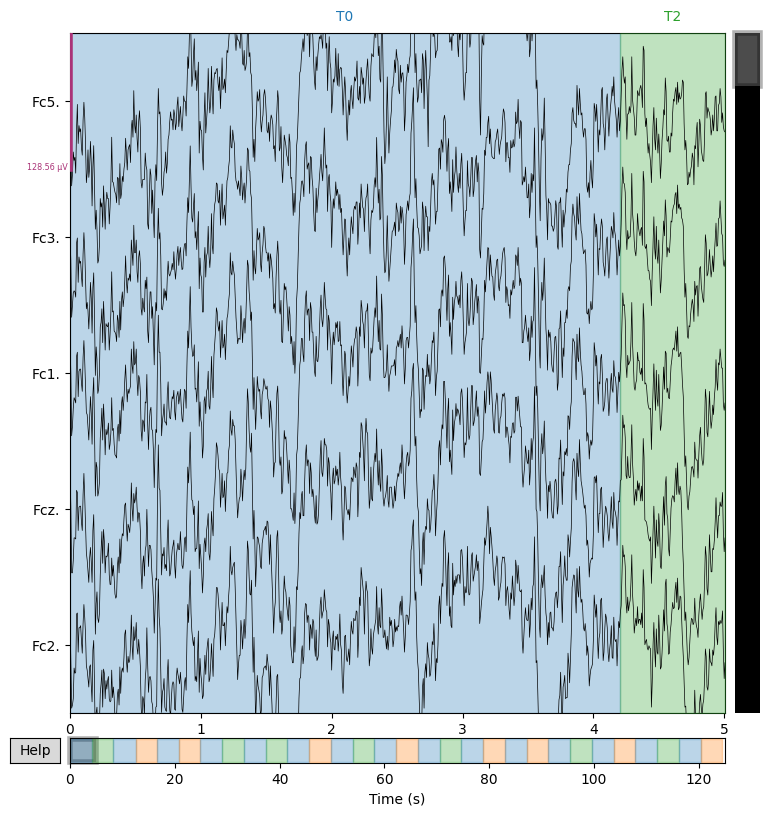

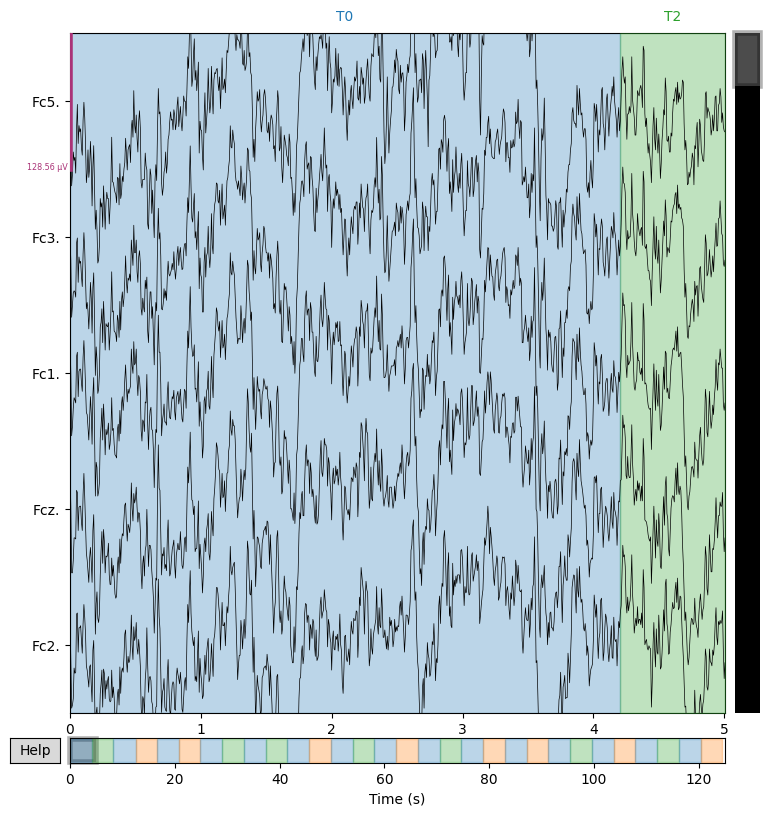

In [41]:
data_path = mne.datasets.eegbci.load_data(subject=1, runs= 4)
raw = mne.io.read_raw_edf(data_path[0], preload=True)

raw.plot(duration=5, n_channels=5, scalings='auto', title='Raw EEG Data', show=True, block=True)

In [42]:
from src.eeg_processor import EEGProcessor

# 1. 启动流水线并完成数据清洗和特征提取
pipeline = EEGProcessor(subject=1, runs=4)
pipeline.load_data()
pipeline.filter_data()
pipeline.extract_features()

# 2. 调参测试 A：使用 500 棵树的随机森林
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=500, random_state=42)
pipeline.train_and_evaluate(model=rf_model)

# 3. 调参测试 B：换成支持向量机 (SVM)
from sklearn.svm import SVC
svm_model = SVC(kernel='linear')
pipeline.train_and_evaluate(model=svm_model)

ImportError: cannot import name 'EEGProcessor' from 'src.eeg_processor' (d:\Users\User\Desktop\tommy脑电波project\src\eeg_processor.py)